# 0. Data Preparation: NEA Historical Rainfall

This notebook inspects and cleans the raw NEA rainfall datasets for 2017–2024 using PySpark. It examines the columns, data types, rainfall values, and completeness of records across stations and years to identify data quality issues. It then applies and documents the necessary cleaning steps and saves a cleaned dataset for use in Task 1 and Task 2.

## 0.1 Spark Session

In [16]:
import socket
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession

In [17]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-ashley-1-m
Spark master:  yarn
Spark version: 3.5.3


In [18]:
!gcloud storage ls gs://dsa5208-rainfall-sixing-data/raw/

gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2017).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2018).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2019).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2020).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2021).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2022).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2023).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2024).csv


## 0.2 Reading the Raw Rainfall Files (2017–2024)

In [19]:
DATA = "gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore*.csv"

rain = spark.read.csv(DATA, header=True)


## 0.3 Inspecting the Schema and Sample Data

This section examines the column names, data types, and sample records in the raw rainfall datasets to understand how the data is structured and identify any formatting or data type issues that may require cleaning.

In [20]:
# Inspect column names and data types
rain.printSchema()

# Display 10 sample records
rain.show(10, truncate=False)

# Dataset size
print(f"Number of rows: {rain.count():,}")
print(f"Number of columns: {len(rain.columns)}")


root
 |-- date: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- update_timestamp: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: string (nullable = true)
 |-- location_latitude: string (nullable = true)
 |-- reading_update_timestamp: string (nullable = true)
 |-- reading_value: string (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)

+----------+-------------------------+-------------------------+----------+----------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|date      |timestamp                |update_timestamp         |station_id|station_name          |station_device_id|location_longitude|location_latitude|reading_update_timestamp |reading_value|reading_type    

Number of rows: 48,538,713
Number of columns: 12


- The dataset contains **48,538,713 rows and 12 columns**.
- All columns are strings; dates, timestamps, rainfall values, and coordinates require type conversion.
- The sample shows different stations at the same timestamp, all recording **0.0 mm** of rainfall.
- All columns allow null values; further checks are needed to identify actual missing values.

## 0.4 Converting Data Types

All columns were loaded as strings. Convert them to suitable types to support accurate filtering, calculations, and time-based analysis:

- Convert dates and timestamps to date/time types, using Singapore Time.
- Convert rainfall readings and coordinates to numeric types.
- Keep station identifiers and descriptive fields as strings.

In [21]:
from pyspark.sql import functions as F

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

rain = (
    rain
    .withColumn("date", F.to_date("date", "yyyy-MM-dd"))
    .withColumn("timestamp", F.to_timestamp("timestamp"))
    .withColumn("update_timestamp", F.to_timestamp("update_timestamp"))
    .withColumn(
        "reading_update_timestamp",
        F.to_timestamp("reading_update_timestamp")
    )
    .withColumn("reading_value", F.col("reading_value").cast("double"))
    .withColumn("location_latitude", F.col("location_latitude").cast("double"))
    .withColumn("location_longitude", F.col("location_longitude").cast("double"))
)

# Verify the updated schema and sample records
rain.printSchema()
rain.show(5, truncate=False)

root
 |-- date: date (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- update_timestamp: timestamp (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: double (nullable = true)
 |-- location_latitude: double (nullable = true)
 |-- reading_update_timestamp: timestamp (nullable = true)
 |-- reading_value: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)

+----------+-------------------+-------------------+----------+-------------------+-----------------+------------------+-----------------+------------------------+-------------+-----------------------------+------------+
|date      |timestamp          |update_timestamp   |station_id|station_name       |station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type                 |reading_uni

## 0.5 Checking Missing Values
Check all columns for null values, text columns for blanks and missing-value markers, and numeric columns for NaN values.

In [22]:
from pyspark.sql import functions as F
rain.select([

    F.sum(F.col(c).isNull().cast("long")).alias(c)
    for c in rain.columns
]).show(truncate = False)

+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+
|date|timestamp|update_timestamp|station_id|station_name|station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type|reading_unit|
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+
|0   |0        |0               |0         |0           |0                |0                 |0                |0                       |0            |0           |0           |
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+



All 12 columns contain **zero null values**. This confirms that no nulls are present in the current dataset, but separate checks are needed for blank strings, text markers such as "NA", numeric NaN values, and missing observation records.

In [23]:
string_cols = [
    name for name, dtype in rain.dtypes
    if dtype == "string"
]

rain.select([
    F.sum(
        F.upper(F.trim(F.col(c)))
        .isin("", "NA", "N/A", "NULL", "NONE", "NAN")
        .cast("long")
    ).alias(c)
    for c in string_cols
]).show(truncate=False)

+----------+------------+-----------------+------------+------------+
|station_id|station_name|station_device_id|reading_type|reading_unit|
+----------+------------+-----------------+------------+------------+
|0         |0           |0                |0           |0           |
+----------+------------+-----------------+------------+------------+



All string columns were checked for blank or whitespace-only values and common missing-value placeholders (`NA`, `N/A`, `NULL`, `NONE`, and `NAN`). Values were trimmed and converted to uppercase before comparison to account for extra spaces and differences in letter case. The results showed zero matches across all 12 columns.

## 0.6 Checking Duplicates

Duplicates are checked at two levels: identical records across all columns and repeated observations for the same station and timestamp. These checks help identify records that could cause rainfall to be counted more than once.

### 0.6.1 Checking Exact Duplicate Rows

Rows are grouped by all columns, and the number of occurrences of each unique row is counted. Groups with more than one occurrence indicate exact duplicates.

In [24]:
exact_duplicate_rows= (
    rain.groupBy(*rain.columns)
            .count()
            .filter(F.col("count") > 1)

)

exact_duplicate_rows.show(20, truncate=False)


+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+
|date|timestamp|update_timestamp|station_id|station_name|station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type|reading_unit|count|
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+



The check returned no rows, indicating that no exact duplicate records were found across all columns.

### 0.6.2 Checking Repeated Station–Timestamp Combinations

Previously, we checked for rows that match across all columns. Now, we check whether the same station has multiple records for the same five-minute observation time, even if other fields differ. This helps flag possible double-counting of rainfall.

In [25]:
repeated_station_timestamps = (
    rain.select("station_id", "timestamp")
        .groupBy("station_id", "timestamp")
        .count()
        .filter(F.col("count") > 1)
)

repeated_station_timestamps.show(20, truncate=False)

+----------+---------+-----+
|station_id|timestamp|count|
+----------+---------+-----+
+----------+---------+-----+



No repeated station–timestamp combinations were found. Each station has at most one record for any given observation timestamp.

## 0.7 Exploring Column Distributions

Columns are grouped by their data type and meaning to examine rainfall values, station frequencies, geographic locations, observation and update times, and measurement types and units. These summaries help identify patterns, unusual values and inconsistencies in the dataset.

### 0.7.1 Rainfall Distribution

The distribution of `reading_value` is summarised using the minimum, maximum, mean, standard deviation and selected percentiles. These statistics describe the range and variability of five-minute rainfall amounts, including zero-rainfall readings.

In [26]:
rain.agg(
    F.min("reading_value").alias("min_rainfall"),
    F.max("reading_value").alias("max_rainfall"),
    F.mean("reading_value").alias("mean_rainfall"),
    F.stddev("reading_value").alias("stddev_rainfall"),
    F.percentile_approx("reading_value", 0.25).alias("p25"),
    F.percentile_approx("reading_value", 0.50).alias("median"),
    F.percentile_approx("reading_value", 0.75).alias("p75"),
    F.percentile_approx("reading_value", 0.95).alias("p95"),
    F.percentile_approx("reading_value", 0.99).alias("p99")
).show(truncate=False)

+------------+------------+--------------------+----------------+---+------+---+---+---+
|min_rainfall|max_rainfall|mean_rainfall       |stddev_rainfall |p25|median|p75|p95|p99|
+------------+------------+--------------------+----------------+---+------+---+---+---+
|0.0         |37.2        |0.025303765871176605|0.27499070426794|0.0|0.0   |0.0|0.0|0.6|
+------------+------------+--------------------+----------------+---+------+---+---+---+



- Five-minute rainfall ranges from **0 to 37.2 mm**.
- Mean rainfall is **0.0253 mm**, with a standard deviation of **0.2750 mm**.
- The approximate **95th percentile is 0 mm**, suggesting roughly 95% or more of readings record no rainfall.
- The approximate **99th percentile is 0.6 mm**.
- The distribution is **strongly right-skewed**, dominated by dry intervals with relatively few large readings.
- The maximum of **37.2 mm** should be investigated before being classified as an error.

Next, we plot the distribution of positive five-minute rainfall amounts, excluding zero readings to examine rainfall patterns during wet intervals.

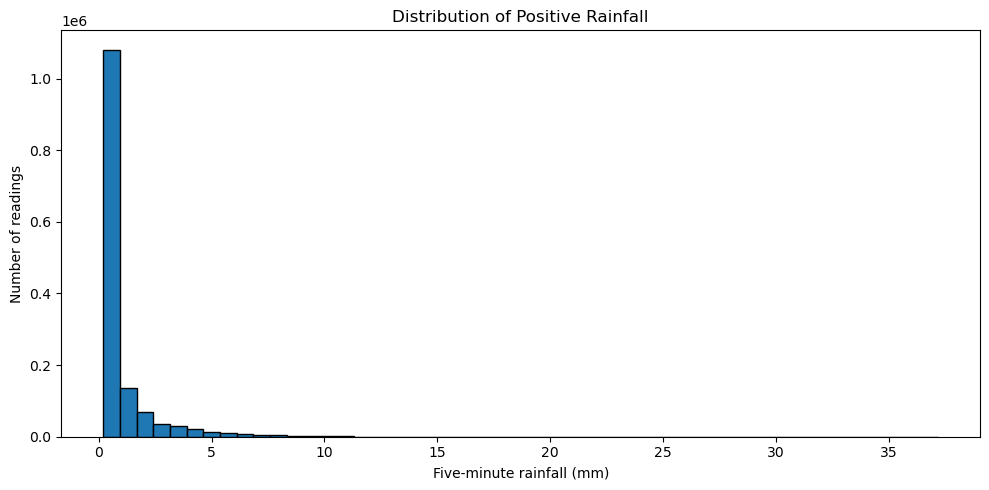

In [27]:
positive_pd = (
    rain.select("reading_value")
        .filter(F.col("reading_value") > 0)
        .toPandas()
)

plt.figure(figsize=(10, 5))
plt.hist(positive_pd["reading_value"], bins=50, edgecolor="black")
plt.title("Distribution of Positive Rainfall")
plt.xlabel("Five-minute rainfall (mm)")
plt.ylabel("Number of readings")
plt.tight_layout()
plt.show()

- Positive rainfall is **strongly right-skewed**, with most readings concentrated at low rainfall amounts.
- The frequency decreases rapidly as rainfall increases, indicating that large five-minute rainfall amounts are relatively rare.
- The long right tail extends to **37.2 mm**, although the largest readings are difficult to see on this scale.
- Even after excluding zero readings, small rainfall amounts dominate the distribution.

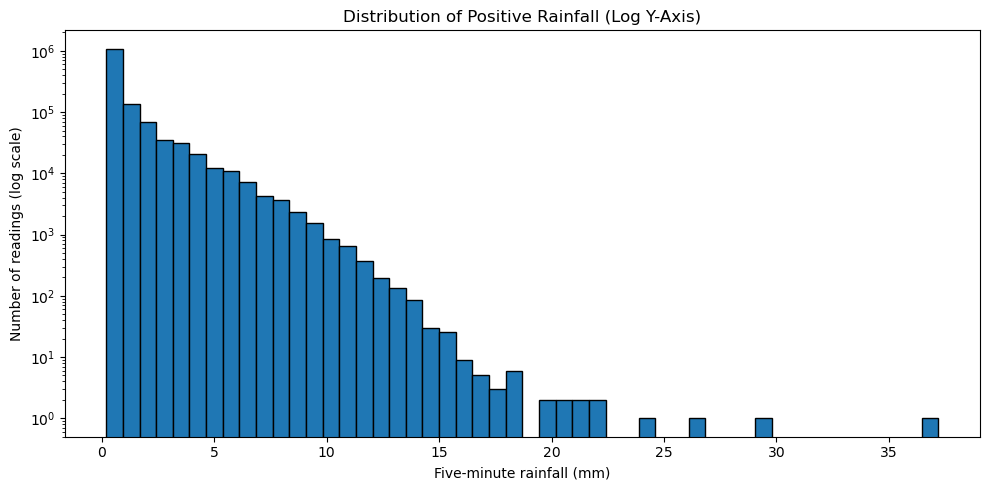

In [28]:
plt.figure(figsize=(10, 5))
plt.hist(positive_pd["reading_value"], bins=50, edgecolor="black")

plt.yscale("log")
plt.title("Distribution of Positive Rainfall (Log Y-Axis)")
plt.xlabel("Five-minute rainfall (mm)")
plt.ylabel("Number of readings (log scale)")

plt.tight_layout()
plt.show()

- The logarithmic y-axis reveals rare, large rainfall readings that were difficult to see in the original histogram.
- Counts generally decrease as rainfall amounts increase, confirming a strongly right-skewed distribution.
- Readings above **20 mm per five-minute interval** are very rare, with only a few observations in the visible bins.
- The isolated readings near **30–37.2 mm** warrant investigation, but the histogram alone does not establish that they are errors.

### 0.7.2 Station and Device Distribution

Distinct station IDs, station names and device IDs are examined alongside their record counts to understand station coverage. Station–name and station–device mappings are also checked for consistency.

In [29]:
rain.agg(
    F.countDistinct("station_id").alias("n_station_id"),
    F.countDistinct("station_name").alias("n_station_name"),
    F.countDistinct("station_device_id").alias("n_device_id"),
).show()

+------------+--------------+-----------+
|n_station_id|n_station_name|n_device_id|
+------------+--------------+-----------+
|          91|           117|         91|
+------------+--------------+-----------+



- The dataset contains **91 distinct station IDs**, **117 distinct station names** and **91 distinct device IDs**.
- The higher number of station names suggests that some station IDs are associated with multiple names. Further checks are needed to confirm this.
- Equal counts of station IDs and device IDs do not necessarily indicate a one-to-one relationship.

In [31]:
# We therefore examine each station ID to identify those associated with multiple names or device IDs.

station_mapping_check = (
    rain.groupBy("station_id")
        .agg(
            F.countDistinct("station_name").alias("n_names"),
            F.countDistinct("station_device_id").alias("n_devices"),
            F.count("*").alias("n_readings")
        )
        .filter(
            (F.col("n_names") > 1) | (F.col("n_devices") > 1)
        )
        .orderBy(F.desc("n_names"))


)

station_mapping_check.show(100, truncate=False)

+----------+-------+---------+----------+
|station_id|n_names|n_devices|n_readings|
+----------+-------+---------+----------+
|S216      |3      |1        |468538    |
|S217      |2      |1        |469750    |
|S212      |2      |1        |426904    |
|S222      |2      |1        |470263    |
|S06       |2      |1        |40141     |
|S210      |2      |1        |464430    |
|S223      |2      |1        |468137    |
|S226      |2      |1        |467254    |
|S220      |2      |1        |470307    |
|S215      |2      |1        |671916    |
|S203      |2      |1        |460068    |
|S230      |2      |1        |469178    |
|S214      |2      |1        |466740    |
|S209      |2      |1        |465941    |
|S229      |2      |1        |470045    |
|S219      |2      |1        |469939    |
|S224      |2      |1        |468750    |
|S208      |2      |1        |470297    |
|S218      |2      |1        |470204    |
|S211      |2      |1        |465619    |
|S201      |2      |1        |4702

- **26 station IDs** are associated with multiple names: **S216 has three names**, while the other **25 stations have two names each**.
- All flagged stations have **one device ID**; no station was flagged for having multiple device IDs.
- The associated names should be inspected to determine whether they reflect naming variations or changes over time.
- `n_readings` represents the total records for each station, not the number of duplicate records.

In [32]:
station_names = (
    rain.groupBy("station_id")
        .agg(
            F.sort_array(
                F.collect_set("station_name")
            ).alias("station_names")
        )
        .filter(F.size("station_names") > 1)
        .orderBy("station_id")
)

station_names.show(100, truncate=False)

+----------+-----------------------------------------------+
|station_id|station_names                                  |
+----------+-----------------------------------------------+
|S06       |[Paya Lebar, S06]                              |
|S201      |[Clementi Park, S201]                          |
|S203      |[Pasir Panjang, S203]                          |
|S207      |[Bedok Road, S207]                             |
|S208      |[Changi East Close, S208]                      |
|S209      |[S209, Yishun Ring Road]                       |
|S210      |[S210, Woodlands Centre]                       |
|S211      |[Kranji Road, S211]                            |
|S212      |[S212, Tampines Avenue 9]                      |
|S213      |[Coronation Walk, S213]                        |
|S214      |[S214, Tanjong Rhu]                            |
|S215      |[GEYLANG EAST CENTRAL, Geylang East Central]   |
|S216      |[Ang Mo Kio Ave 10, Ang Mo Kio Avenue 10, S216]|
|S217      |[Bishan Stre

- **25 of the 26 flagged stations** have their station ID recorded as a name alongside a descriptive location name, such as `[Paya Lebar, S06]`.
- **S215** has a capitalisation difference: `GEYLANG EAST CENTRAL` and `Geylang East Central`.
- **S216** has an abbreviation difference (`Ave` versus `Avenue`) as well as its station ID used as a name.
- These results suggest naming inconsistencies rather than evidence of station relocation. Grouping by `station_id` avoids splitting a station’s records across these name variations.

We clean three naming inconsistencies:
1. Replace station IDs used as names, such as `S211`, with their descriptive names.
2. Standardise capitalisation, such as `GEYLANG EAST CENTRAL` to `Geylang East Central`.
3. Expand `Ave` to `Avenue`.

The mapping is built from names already present in the dataset. Cleaned names are stored in `station_name_clean`, preserving the original names.

In [33]:
# Step 1: Standardise capitalisation and expand "Ave" to "Avenue"
name_candidates = rain.select(
    "station_id",
    F.initcap(
        F.regexp_replace(
            F.trim("station_name"),
            r"(?i)\bAve\b",
            "Avenue"
        )
    ).alias("clean_name")
)

# Step 2: Exclude blank names and names that are just station IDs
# For example, keep "Kranji Road" but exclude "S211"
name_candidates = name_candidates.filter(
    (F.upper(F.col("clean_name")) != F.upper(F.trim("station_id"))) &
    (F.col("clean_name") != "")
)

# Step 3: Build a dynamic mapping for stations with exactly one cleaned name
# F.min() retrieves that name; stations with multiple names are excluded
station_name_mapping = (
    name_candidates.groupBy("station_id")
        .agg(
            F.countDistinct("clean_name").alias("n_names"),
            F.min("clean_name").alias("mapped_name")
        )
        .filter(F.col("n_names") == 1)
        .select("station_id", "mapped_name")
)

# Step 4: Display the mapping for review
station_name_mapping.show(100, truncate=False)

# Step 5: Apply the mapping and preserve the original station_name column
# If no mapping exists, retain the original name
rain = (
    rain.join(station_name_mapping, on="station_id", how="left")
        .withColumn(
            "station_name_clean",
            F.coalesce("mapped_name", "station_name")
        )
        .drop("mapped_name")
)



+----------+---------------------------+
|station_id|mapped_name                |
+----------+---------------------------+
|S06       |Paya Lebar                 |
|S07       |Lornie Road                |
|S08       |Upper Thomson Road         |
|S100      |Woodlands Road             |
|S101      |Corporation Road           |
|S102      |Semakau Landfill           |
|S103      |Dairy Farm Road            |
|S104      |Woodlands Avenue 9         |
|S105      |Admiralty Road West        |
|S106      |Pulau Ubin                 |
|S107      |East Coast Parkway         |
|S108      |Marina Gardens Drive       |
|S109      |Ang Mo Kio Avenue 5        |
|S11       |Choa Chu Kang Road         |
|S110      |Serangoon North Avenue 4   |
|S111      |Scotts Road                |
|S112      |Lim Chu Kang Road          |
|S113      |Marine Parade Road         |
|S114      |Choa Chu Kang Avenue 4     |
|S115      |Tuas South Avenue 3        |
|S116      |West Coast Highway         |
|S117      |Bany

### 0.7.3 Geographic Distribution

Latitude and longitude ranges are examined to understand the geographic extent of the stations. Distinct station–coordinate combinations are plotted to show their spatial distribution without giving more weight to stations with more readings. Stations associated with multiple coordinate pairs are also flagged for investigation.

In [34]:
# Coordinate ranges — should sit within Singapore's bounds
rain.agg(
    F.min("location_latitude").alias("lat_min"),
    F.max("location_latitude").alias("lat_max"),
    F.min("location_longitude").alias("lon_min"),
    F.max("location_longitude").alias("lon_max"),
).show()

+-------+-------+---------+--------+
|lat_min|lat_max|  lon_min| lon_max|
+-------+-------+---------+--------+
|  1.189|1.45817|103.61843|104.0307|
+-------+-------+---------+--------+



The observed latitude and longitude ranges fall within Singapore’s broad geographic extent reported by SingStat. This provides an initial location sanity check, although it does not confirm that every station lies within Singapore’s actual boundary.

In [35]:
# Does any station report more than one coordinate pair?
rain.groupBy("station_id").agg(
    F.countDistinct("location_latitude").alias("n_lat"),
    F.countDistinct("location_longitude").alias("n_lon"),
).filter((F.col("n_lat") > 1) | (F.col("n_lon") > 1)) \
 .show(50, truncate=False)

+----------+-----+-----+
|station_id|n_lat|n_lon|
+----------+-----+-----+
|S113      |2    |2    |
+----------+-----+-----+



Only station **S113** has multiple recorded coordinate values, with **two distinct latitudes and two distinct longitudes**. This may reflect a location change or a coordinate correction. The actual coordinate pairs and their observation dates should be inspected to understand the difference.

In [36]:
(
    rain.filter(F.col("station_id") == "S113")
        .groupBy("location_latitude", "location_longitude")
        .agg(
            F.min("timestamp").alias("first_observed"),
            F.max("timestamp").alias("last_observed"),
            F.count("*").alias("n_readings")
        )
        .orderBy("first_observed")
        .show(truncate=False)
)

+-----------------+------------------+-------------------+-------------------+----------+
|location_latitude|location_longitude|first_observed     |last_observed      |n_readings|
+-----------------+------------------+-------------------+-------------------+----------+
|1.30655          |103.91074         |2017-01-01 08:04:59|2017-04-25 11:24:59|32180     |
|1.30648          |103.9104          |2017-04-25 11:20:00|2024-12-31 23:55:00|769603    |
+-----------------+------------------+-------------------+-------------------+----------+



- Station **S113** has two recorded coordinate pairs, with a transition around **25 April 2017**.
- The locations are approximately **39 metres apart**, suggesting a small location adjustment or coordinate correction rather than a major relocation.
- Their observation periods overlap by about **five minutes**, so the transition is not a clean chronological switch.
- The coordinates alone cannot confirm the cause. Both pairs are retained unless further station metadata supports a correction.

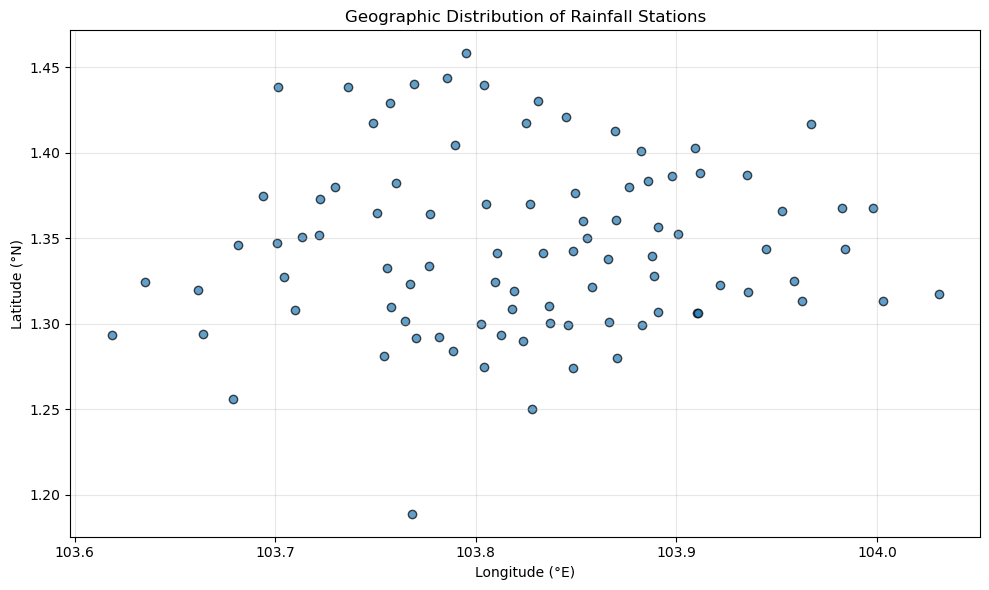

In [37]:

# 1. Select station IDs and coordinates
# Remove missing coordinates and repeated station–coordinate combinations
# This prevents stations with more rainfall records from being plotted repeatedly
station_locations = (
    rain.select(
        "station_id",
        "location_latitude",
        "location_longitude"
    )
    .dropna(subset=["location_latitude", "location_longitude"])
    .distinct()
)

# 2. Convert only the small table of distinct locations to pandas for plotting
locations_pd = station_locations.toPandas()

# 3. Plot station locations to examine their geographic distribution
# Longitude is the horizontal axis; latitude is the vertical axis
plt.figure(figsize=(10, 6))

plt.scatter(
    locations_pd["location_longitude"],
    locations_pd["location_latitude"],
    alpha=0.7,
    edgecolors="black"
)

plt.title("Geographic Distribution of Rainfall Stations")
plt.xlabel("Longitude (°E)")
plt.ylabel("Latitude (°N)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Each point represents a distinct station–coordinate combination
# S113 retains both recorded locations, which may visually overlap

- Station locations are spread across the observed geographic area, with uneven spacing.
- Locations appear more concentrated in the central part of the plot, with fewer points near the outer edges.
- This plot combines locations observed across 2017–2024; it does not imply that all stations operated simultaneously.
- S113’s two recorded locations are very close together and may appear as one overlapping point.

### 0.7.4 Measurement Type and Unit Consistency

Measurement types and units are checked to confirm that rainfall readings are comparable before aggregation and analysis.

In [38]:
# Check the distinct measurement type–unit combinations and their record counts
measurement_check = (
    rain.groupBy("reading_type", "reading_unit")
        .count()
        .orderBy(F.desc("count"))
)

measurement_check.show(truncate=False)

+-----------------------------+------------+--------+
|reading_type                 |reading_unit|count   |
+-----------------------------+------------+--------+
|TB1 Rainfall 5 Minute Total F|mm          |48538713|
+-----------------------------+------------+--------+



All **48,538,713 records** use the same measurement type, **TB1 Rainfall 5 Minute Total F**, and unit, **millimetres (mm)**. This confirms consistent measurement types and units across the dataset, so no unit conversion is needed before analysis.